
# Pitch Basics

First we import the Pitch classes and matplotlib


In [2]:
%%script false --no-raise-error

!pip install mplsoccer pandas-summary

import matplotlib.pyplot as plt

from mplsoccer import Pitch, VerticalPitch

plt.rcdefaults() # cancel the xqcd

## Draw a pitch on a new axis
Let's plot on a new axis first.



In [3]:
# import csv

# # Define the path to your CSV file
# csv_file_path = 'Session-Mateo-gps.csv'

# # Initialize an empty list to store the data
# sheet = []

# # Open and read the CSV file
# with open(csv_file_path, 'r') as file:
#     csv_reader = csv.reader(file)
#     header = next(csv_reader)  # Read the header row (if it exists)
#     sheet.append(header)  # Add the header to the data list (optional)
    
#     for row in csv_reader:
#         sheet.append(row)

# # Display the data
# for row in sheet[:10]:
#     print(row)

In [4]:
import pandas as pd
csv_file_path = 'Session-Mateo-gps.csv'
df = pd.read_csv(csv_file_path)
df.columns = ['Player Display Name', 'Time', 'Elapsed Time (s)', 'Lat', 'Lon', 'Speed km/h', 'Instantaneous Acceleration Impulse', 'Heart Rate (bpm)', 'basura']
df.columns = df.columns.str.strip()

#https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu
# -34.794926, -56.148368
# -34.795816, -56.147428

lat_lower_bound = -34.795816
lat_upper_bound = -34.794926
lon_lower_bound = -56.148368
lon_upper_bound = -56.147428
fix_df = df[(df['Lat'] > lat_lower_bound) & (df['Lat'] < lat_upper_bound)]
fix_df = fix_df[(fix_df['Lon'] > lon_lower_bound) & (fix_df['Lon'] < lon_upper_bound)]

In [5]:
fix_df

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura
41,Mateo Molinari,09:42:09.60,0.099999,-34.795292,-56.147644,1.720001,4.000003,0,NaN
41,Mateo Molinari,09:42:09.70,0.199999,-34.795292,-56.147644,2.270002,5.500004,0,NaN
41,Mateo Molinari,09:42:09.80,0.299998,-34.795293,-56.147643,1.720001,5.500004,0,NaN
41,Mateo Molinari,09:42:09.90,0.399997,-34.795293,-56.147643,0.000000,17.200014,0,NaN
41,Mateo Molinari,09:42:10.00,0.499997,-34.795293,-56.147643,0.000000,0.000000,0,NaN
...,...,...,...,...,...,...,...,...,...
41,Mateo Molinari,10:56:53.40,4483.899996,-34.795813,-56.148027,4.220003,6.000005,0,NaN
41,Mateo Molinari,10:56:53.50,4483.999996,-34.795813,-56.148028,4.070003,1.500001,0,NaN
41,Mateo Molinari,10:56:53.60,4484.099995,-34.795814,-56.148029,3.900003,1.700001,0,NaN
41,Mateo Molinari,10:56:53.70,4484.199995,-34.795814,-56.148030,3.680003,2.200002,0,NaN



# Analisis Descriptivo


In [6]:
summary_lon = fix_df['Lon'].describe()
summary_lat = fix_df['Lat'].describe()

print("summary_lon:\n", summary_lon)
print("summary_lat:\n", summary_lat)

summary_lon:
 count    40205.000000
mean       -56.147847
std          0.000155
min        -56.148276
25%        -56.147931
50%        -56.147858
75%        -56.147810
max        -56.147460
Name: Lon, dtype: float64
summary_lat:
 count    40205.000000
mean       -34.795241
std          0.000114
min        -34.795816
25%        -34.795313
50%        -34.795259
75%        -34.795176
max        -34.794926
Name: Lat, dtype: float64


In [7]:
from pandas_summary import DataFrameSummary

# Get a summary of the DataFrame

numeric_columns = fix_df.select_dtypes(include=['number'])

summary = DataFrameSummary(numeric_columns)

# Print the summary
print(summary.summary())

             Elapsed Time (s)        Lat        Lon Speed km/h  \
count                 40205.0    40205.0    40205.0    40205.0   
mean              2379.600823 -34.795241 -56.147847   4.502214   
std               1288.660217   0.000114   0.000155   5.057943   
min                  0.099999 -34.795816 -56.148276        0.0   
25%               1395.599993 -34.795313 -56.147931        0.0   
50%               2467.600001 -34.795259 -56.147858   3.230003   
75%               3472.799996 -34.795176  -56.14781   6.390005   
max               4484.299994 -34.794926  -56.14746  27.530022   
counts                  40205      40205      40205      40205   
uniques                 40137       3510       4270       2237   
missing                     0          0          0          0   
missing_perc               0%         0%         0%         0%   
types                 numeric    numeric    numeric    numeric   

             Instantaneous Acceleration Impulse Heart Rate (bpm)   basura  

In [8]:
# Get the minimum and maximum values for 'Column1'
min_value_lat = fix_df['Lat'].min()
max_value_lat = fix_df['Lat'].max()

# Get the minimum and maximum values for 'Column2'
min_value_lon = fix_df['Lon'].min()
max_value_lon = fix_df['Lon'].max()

print(f"Minimum of player min_value_lat: {min_value_lat}")
print(f"Maximum of player max_value_lat: {max_value_lat}")
print(f"Minimum of player min_value_lon: {min_value_lon}")
print(f"Maximum of player max_value_lon: {max_value_lon}")

Minimum of player min_value_lat: -34.7958155
Maximum of player max_value_lat: -34.79492617
Minimum of player min_value_lon: -56.14827583
Maximum of player max_value_lon: -56.14745983


In [9]:
# puntos en cancha
# https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu

# -34.794926, -56.148368
# -34.795816, -56.147428

# Coordenadas de Los cespedes
lat_min = -34.795816
lat_max = -34.794926
lon_min = -56.148368
lon_max = -56.147428


# Trigonometria


In [10]:
import numpy as np

# Define the GPS coordinates of four points (A, B, C, D) on the field
point_A = (-34.794927, -56.148375)
point_B = (-34.794853, -56.147571)
point_C = (-34.795902, -56.148234)
point_D = (-34.795815, -56.147426)

# Calculate the length and width of the rectangle
length = np.sqrt((point_A[0] - point_B[0])**2 + (point_A[1] - point_B[1])**2)
width = np.sqrt((point_A[0] - point_C[0])**2 + (point_A[1] - point_C[1])**2)

# Determine which sides are length and width
if length > width:
    length, width = width, length  # Swap if necessary

# Calculate the angle between the length side and the North direction
rotation_angle_radians = np.arctan2(point_B[1] - point_A[1], point_B[0] - point_A[0])
rotation_angle_degrees = np.degrees(rotation_angle_radians)

# Ensure the angle is positive (between 0 and 360 degrees)
if rotation_angle_degrees < 0:
    rotation_angle_degrees += 360

print(f"Rotation Angle: {rotation_angle_degrees} degrees")

Rotation Angle: 84.74132377744776 degrees



# Normalizacion de las coordenadas para el Pitch


In [11]:
import pandas as pd
import numpy as np

# Define the rotation angle in degrees
rotation_angle_degrees = 84.74132377744776  # Degrees rotated from North to West

# Convert the rotation angle to radians
rotation_angle_radians = np.radians(rotation_angle_degrees)

# Define the size of the soccer field in meters
soccer_field_length = 80  # In meters
soccer_field_width = 120  # In meters

# Function to apply the rotation to coordinates
def rotate_coordinates(row):
    lat, lon = row['Lat'], row['Lon']
    new_lat = lat * np.cos(rotation_angle_radians) - lon * np.sin(rotation_angle_radians)
    new_lon = lat * np.sin(rotation_angle_radians) + lon * np.cos(rotation_angle_radians)
    return pd.Series({'Lat': new_lat, 'Lon': new_lon})


df = fix_df
# Apply the rotation to the coordinates
df[['Lat', 'Lon']] = df.apply(rotate_coordinates, axis=1)

# Scale and normalize the coordinates to the soccer field dimensions
df['Lat_normalized'] = (df['Lat'] - df['Lat'].min()) / (df['Lat'].max() - df['Lat'].min()) * soccer_field_length
df['Lon_normalized'] = (df['Lon'] - df['Lon'].min()) / (df['Lon'].max() - df['Lon'].min()) * soccer_field_width


# Display the DataFrame with normalized coordinates
print(df)

   Player Display Name         Time  Elapsed Time (s)        Lat        Lon  \
41      Mateo Molinari  09:42:09.60          0.099999  52.722250 -39.794908   
41      Mateo Molinari  09:42:09.70          0.199999  52.722249 -39.794908   
41      Mateo Molinari  09:42:09.80          0.299998  52.722248 -39.794908   
41      Mateo Molinari  09:42:09.90          0.399997  52.722248 -39.794908   
41      Mateo Molinari  09:42:10.00          0.499997  52.722248 -39.794908   
..                 ...          ...               ...        ...        ...   
41      Mateo Molinari  10:56:53.40       4483.899996  52.722584 -39.795461   
41      Mateo Molinari  10:56:53.50       4483.999996  52.722584 -39.795462   
41      Mateo Molinari  10:56:53.60       4484.099995  52.722585 -39.795463   
41      Mateo Molinari  10:56:53.70       4484.199995  52.722586 -39.795463   
41      Mateo Molinari  10:56:53.80       4484.299994  52.722587 -39.795464   

    Speed km/h  Instantaneous Acceleration Impulse 


# Visualizacion


40205


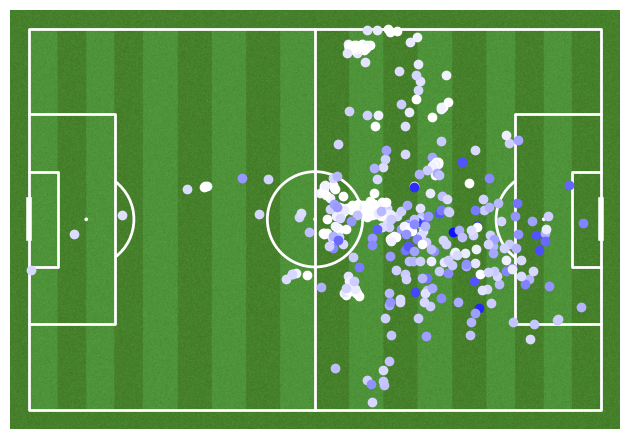

In [12]:
pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw()


print(len(df))

# cancha: 120x80

step = 100
colors = np.linspace(0, 1, len(df))
# Iterar avanzando de 10 en 10 elementos
for i in range(0, len(df), step):
    # color = (1, 1 - colors[i], 1 - colors[i])
    for index, row in df.iloc[i:i+1].iterrows():
        # print(row['Lat_normalized'],row['Lon_normalized'])
        speed = row['Speed km/h']
        normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
        color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
        ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)


plt.show()

In [13]:
speed_df = fix_df[fix_df['Speed km/h'] > 0.5]

In [14]:
def plot_velocidades_altas(v_min, v_max=None, color_param='R', step=1):
    pitch = Pitch(pitch_color='#aabb97', line_color='white',
              stripe_color='#c2d59d', stripe=True)  # optional stripes
    fig, ax = pitch.draw()
    
    speed_df = fix_df[fix_df['Speed km/h'] > v_min]
    str = f'Velocidades > {v_min}km/h'
    
    if v_max:
        speed_df = speed_df[speed_df['Speed km/h'] < v_max]
        str = f'{str} y < {v_max}km/h'
    
    df = speed_df
    
    print("Total de puntos: ", len(df))
    annotation = ax.annotate(str, (60, 10), fontsize=20, ha='center', color="green")
    
    # cancha: 120x80
    colors = np.linspace(0, 1, len(df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
            if color_param == 'R':
                color = (1 - normalized_speed, 0, 0)  # Rojo
            elif color_param == 'G':
                color = (0, 1 - normalized_speed, 0)  # Verde
            elif color_param == 'B':
                color = (0, 0, 1 - normalized_speed)  # Azul
            else:
                color = (1, 1, 1)  # Blanco por defecto
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)

Total de puntos:  55


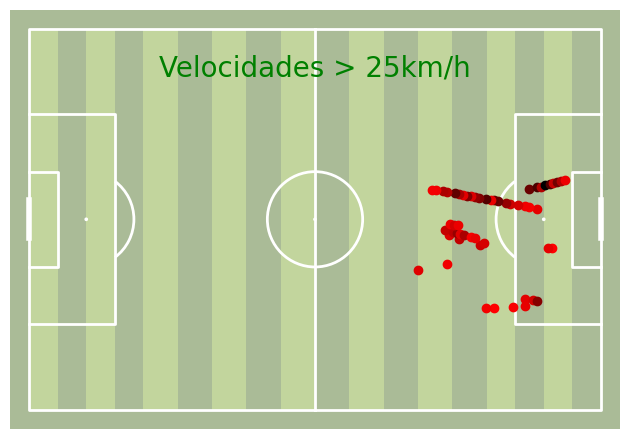

In [15]:
plot_velocidades_altas(25)

Total de puntos:  561


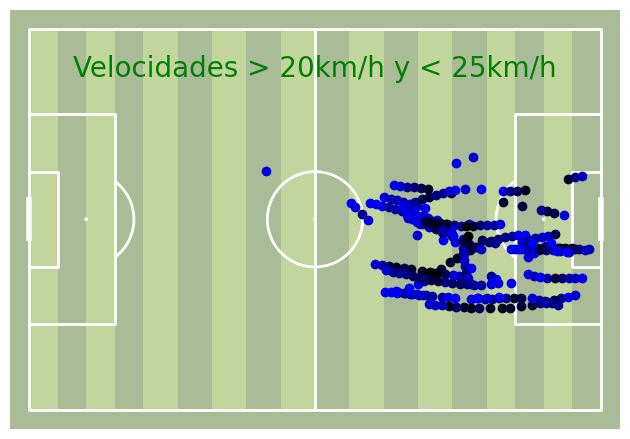

In [16]:
plot_velocidades_altas(20, v_max=25, color_param='B', step=2)

Total de puntos:  1393


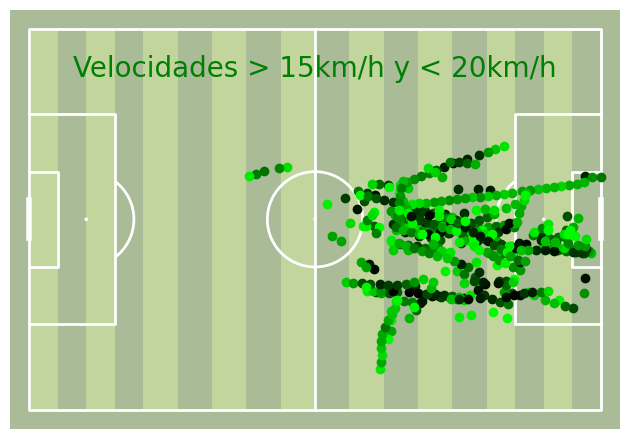

In [17]:
plot_velocidades_altas(15, v_max=20, color_param='G', step=3)

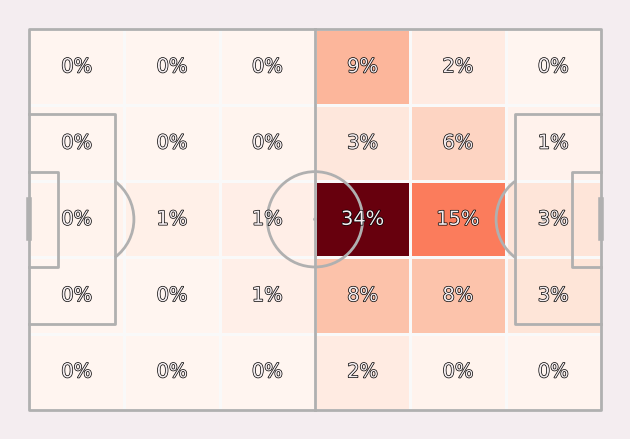

In [18]:
import matplotlib.patheffects as path_effects

path_eff = [path_effects.Stroke(linewidth=1, foreground='black'),
            path_effects.Normal()]

pitch = Pitch(pitch_type='statsbomb', line_zorder=2, pitch_color='#f4edf0')
fig, ax = pitch.draw()
fig.set_facecolor('#f4edf0')

df = fix_df

bin_statistic = pitch.bin_statistic(df['Lon_normalized'], df['Lat_normalized'], statistic='count', bins=(6, 5), normalize=True)
pitch.heatmap(bin_statistic, ax=ax, cmap='Reds', edgecolor='#f9f9f9')
labels = pitch.label_heatmap(bin_statistic, color='#f4edf0', fontsize=14,
                             ax=ax, ha='center', va='center',
                             str_format='{:.0%}', path_effects=path_eff)

In [19]:
import math

df = fix_df
df = df[df['Elapsed Time (s)'] > 0]

# Apply the rotation to the coordinates
df['coord'] = list(zip(df['Lat'], df['Lon'], df['Elapsed Time (s)']))
# Sample GPS coordinate data (latitude, longitude, timestamp)
gps_data = df['coord']

# Function to calculate distance between two GPS coordinates
def calculate_distance(coord1, coord2):
    lat1, lon1, _ = coord1
    lat2, lon2, _ = coord2
    radius = 6371  # Earth's radius in kilometers
    lat1_rad = math.radians(lat1)
    lon1_rad = math.radians(lon1)
    lat2_rad = math.radians(lat2)
    lon2_rad = math.radians(lon2)
    delta_lat = lat2_rad - lat1_rad
    delta_lon = lon2_rad - lon1_rad
    a = math.sin(delta_lat / 2)**2 + math.cos(lat1_rad) * math.cos(lat2_rad) * math.sin(delta_lon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    distance = radius * c
    return distance

# Threshold speed in km/h
threshold_speed = 20

# Variables to keep track of total distance and distance above threshold
total_distance = 0
distance_above_threshold = 0

for i in range(len(df) - 1):
    coord1 = df['coord'].iloc[i]
    coord2 = df['coord'].iloc[i + 1]

    # Calculate the distance between two consecutive coordinates
    distance = calculate_distance(coord1, coord2)

    # Calculate the time elapsed between coordinates (in seconds)
    time_elapsed = 0.1 
    # time_elapsed ----> coord2[2] - coord1[2]
    # print(time_elapsed)

    # Calculate speed (distance / time) in km/h
    speed = (distance / time_elapsed) * 3600

    # Update total distance
    total_distance += distance

    # Check if speed is above the threshold
    if speed >= threshold_speed:
        distance_above_threshold += distance

print(f"Total distance run: {total_distance} km")
print(f"Distance above {threshold_speed} km/h: {distance_above_threshold} km")

Total distance run: 4.523164067268519 km
Distance above 20 km/h: 0.12528047604218287 km


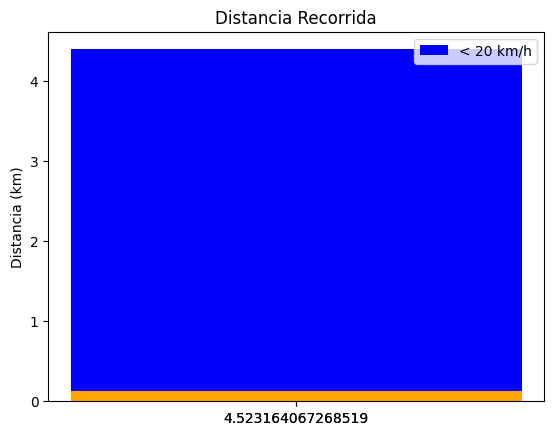

In [20]:
import matplotlib.pyplot as plt

# Distancia recorrida por debajo de threshold_speed km/h
distance_below_threshold = total_distance - distance_above_threshold

# Colores para los segmentos
colors = ['blue', 'orange']

# Etiquetas para los segmentos
labels = [f'< {threshold_speed} km/h', f'>= {threshold_speed} km/h']

# Alturas de los segmentos
heights = [distance_below_threshold, distance_above_threshold]

# Posiciones en el eje X para los segmentos
positions = [0, 0]

# Crear la figura y los ejes
fig, ax = plt.subplots()

# Dibujar el segmento de la barra
ax.bar(positions, heights, color=colors, tick_label=[total_distance])

# Configurar el eje y
ax.set_ylabel('Distancia (km)')

# Configurar el título
ax.set_title('Distancia Recorrida')

# Añadir una leyenda
ax.legend(labels)

# Mostrar la gráfica
plt.show()

In [22]:
import pandas as pd


# Crear un DataFrame de ejemplo con coordenadas y velocidad
df = fix_df

# km/h => m/s
df['Speed m/s'] = list(df['Speed km/h']/3.6)
# df['Acceleration'] = list(df['Speed km/h']/3.6)

# Umbral de aceleración
threshold_acceleration = 4.93  # Ajusta el umbral según sea necesario

# Contador de veces que se supera el umbral de aceleración
count_exceeding_threshold = 0

rows_per_second = 10

when = []

# Iterar a través del DataFrame con saltos de 10 filas
for i in range(0, len(df) - rows_per_second, rows_per_second):
    # Obtener la velocidad actual y la velocidad anterior
    velocity_current = df['Speed m/s'].iloc[i]
    velocity_next = df['Speed m/s'].iloc[i + rows_per_second]

    # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
    acceleration = (velocity_next - velocity_current) / 1.0

    # Comparar la aceleración con el umbral
    if acceleration > threshold_acceleration:
        when.append([i])
        count_exceeding_threshold += 1

print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")


El umbral de aceleración se superó 1 veces.


In [23]:
when

[[8840]]

In [24]:
filas_antes_despues = 10

# DataFrame para almacenar las filas de interés
df_resultado = pd.DataFrame()

# Iterar a través de los índices de interés
for indice in when:
    inicio = max(indice[0] - filas_antes_despues, 0)
    fin = min(indice[0] + filas_antes_despues + 1, len(df))
    filas_seleccionadas = df.iloc[inicio:fin]
    df_resultado = pd.concat([df_resultado, filas_seleccionadas])


In [25]:
df_resultado

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura,Lat_normalized,Lon_normalized,Speed m/s
41,Mateo Molinari,10:02:13.60,1204.100001,52.722686,-39.794585,5.090004,3.300003,0,NaN,60.746966,115.776016,1.413890
41,Mateo Molinari,10:02:13.70,1204.200000,52.722686,-39.794583,5.320004,2.300002,0,NaN,60.758901,115.950337,1.477779
41,Mateo Molinari,10:02:13.80,1204.299999,52.722686,-39.794582,5.370004,0.500000,0,NaN,60.770925,116.125968,1.491668
41,Mateo Molinari,10:02:13.90,1204.399999,52.722686,-39.794581,4.460004,9.100007,0,NaN,60.763324,116.259087,1.238890
41,Mateo Molinari,10:02:33.30,1223.799996,52.722711,-39.794584,4.830004,5.600004,0,NaN,63.166924,115.939199,1.341668
41,Mateo Molinari,10:02:33.40,1223.899995,52.722711,-39.794585,5.650005,8.200007,0,NaN,63.167538,115.718386,1.569446
41,Mateo Molinari,10:02:33.50,1223.999994,52.722711,-39.794586,4.420004,12.300010,0,NaN,63.142966,115.589248,1.227779
41,Mateo Molinari,10:02:33.60,1224.099994,52.722710,-39.794586,2.240002,0.000000,0,NaN,63.092784,115.574309,0.622223
41,Mateo Molinari,10:02:33.70,1224.199993,52.722710,-39.794587,0.000000,0.000000,0,NaN,63.106858,115.550097,0.000000
41,Mateo Molinari,10:02:33.80,1224.300001,52.722710,-39.794586,1.880002,18.800015,0,NaN,63.047000,115.623593,0.522223


21


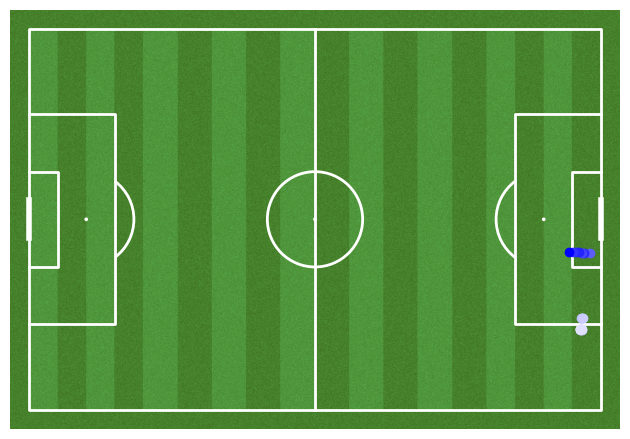

In [26]:
pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw()

df = df_resultado
print(len(df))

# cancha: 120x80

step = 1
colors = np.linspace(0, 1, len(df))
# Iterar avanzando de 10 en 10 elementos
for i in range(0, len(df), step):
    # color = (1, 1 - colors[i], 1 - colors[i])
    for index, row in df.iloc[i:i+1].iterrows():
        # print(row['Lat_normalized'],row['Lon_normalized'])
        speed = row['Speed km/h']
        normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
        color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
        ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)


plt.show()